# 1. From an area to a network

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/01_area_to_network.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/01_area_to_network.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You get the network of an area, look at its modes, draw it and query it.

| Step | Call |
|---|---|
| Get and build an area | `duckosm.network`, or `duckosm.AreaPicker` and `area.build` |
| See what is in the file | `net`, `net.summary()`, `net.columns()` |
| Draw the network | `net.map()`, `net.walking.map()` |
| Query the edges | `net.driving.edges()`, `net.sql()` |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## Quick start

One call gets the OSM file of Monaco and builds two modes, driving and walking. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

In [2]:
net = duckosm.network("Monaco", modes=["driving", "walking"])    # get and build Monaco: a duckosm.Network
net                                                               # the card: the file, and the edges, nodes and km of each mode

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5
walking,11938,4589,260.6,0.0


In [3]:
net.summary()    # one row for each mode

,mode,edges,nodes,km,oneway_km
0,driving,2840,1768,96.2,35.5
1,walking,11938,4589,260.6,0.0


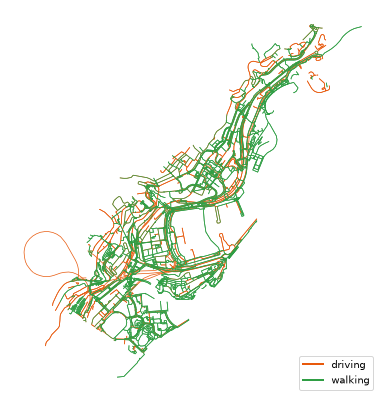

In [4]:
net.map()    # all modes on one map

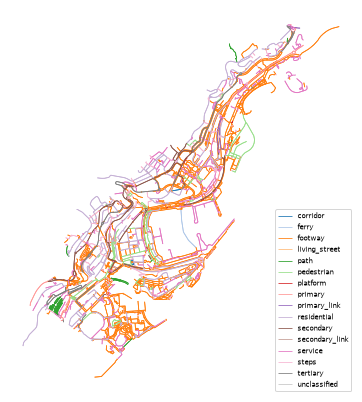

In [5]:
net.walking.map()    # only the walking network: net.walking is the view of one mode

## Choose the area on a map

The widget shows a map. Choose an area with one of the tabs (Search, OSM id, Box, H3 cell, File), then click **Get**. The line under the map shows the Geofabrik extract and its size before the download.

If you do not choose an area, the notebook uses Monaco. The guide is [Choose an area in Jupyter](https://khoshkhah.github.io/duckOSM/guides/area-picker/).

![The AreaPicker widget: the search found Monaco](https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/images/area-picker.png)

In [6]:
picker = duckosm.AreaPicker(out="data")              # the files go into the folder data/
picker.area = {"mode": "place", "place": "Monaco"}   # the area when you choose none on the map
picker                                               # the map

`picker.get()` downloads the extract (when it is not in the cache) and cuts it to the boundary. If you clicked **Get**, the cell waits for that run.

In [7]:
area = picker.result or picker.get()    # the result of Get, or get it now
area                                    # the card: the OSM file and the boundary

boundary: Monaco, OSM relation 1124039, 79.8 km², from Nominatim

,file,size
OSM file,data/monaco.osm.pbf,0.6 MB
boundary,data/monaco.geojson,13 kB


In [8]:
net = area.build(modes=["driving", "walking"])    # build the network of the area
net                                               # the card of the new network

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5
walking,11938,4589,260.6,0.0


## Query the edges

Each row of `<mode>.edges` is one direction of a road. `edge_id` is a `BIGINT` content hash: it stays the same after a rebuild, a cut and an export. Other data joins on it (see notebook 5).

In [9]:
net.columns("driving.edges").head(8)    # the first columns of the table driving.edges and their types

,column_name,column_type
0,edge_id,BIGINT
1,edge_ref,VARCHAR
2,source,BIGINT
3,target,BIGINT
4,osm_id,BIGINT
5,highway,VARCHAR
6,name,VARCHAR
7,oneway,BOOLEAN


In [10]:
edges = net.driving.edges()                                              # the driving edges as a GeoDataFrame
edges[["edge_id", "name", "highway", "length_m", "maxspeed_kmh"]].head()    # five rows

,edge_id,name,highway,length_m,maxspeed_kmh
0,414242052250797,Boulevard du Ténao,residential,44.240875,30.0
1,2214154189574909,NaN,service,24.298845,20.0
2,15757195119014288,Rue du Ténao,residential,9.057960,30.0
3,16871577064511426,NaN,residential,3.996883,30.0
4,21502429769987032,NaN,residential,3.554246,30.0


In [11]:
net.sql("""SELECT highway, count(*) AS edges, round(sum(length_m) / 1000, 1) AS km
           FROM driving.edges GROUP BY highway ORDER BY km DESC LIMIT 8""")    # the road classes, by length

,highway,edges,km
0,residential,919,31.7
1,service,855,23.7
2,secondary,429,14.9
3,tertiary,387,12.5
4,primary,197,11.2
5,primary_link,21,1.1
6,unclassified,13,0.6
7,secondary_link,13,0.4


In [12]:
net.sql("""SELECT name, round(sum(length_m)) AS length_m, count(*) AS edges, any_value(typeof(edge_id)) AS edge_id_type
           FROM driving.edges WHERE name IS NOT NULL GROUP BY name ORDER BY length_m DESC LIMIT 5""")    # the longest named roads

,name,length_m,edges,edge_id_type
0,Boulevard du Larvotto,5305.0,85,BIGINT
1,Boulevard du Jardin Exotique,3280.0,73,BIGINT
2,Avenue Princesse Grace,2576.0,86,BIGINT
3,Avenue Pasteur,2246.0,42,BIGINT
4,Tunnel Albert II,1994.0,7,BIGINT
